# Setup

In [14]:
import os
import glob
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:

DATASET_ROOT = os.path.join("..", "data", "raw", "CIMWV_Dataset_v1", "AnnotatedWindowViewImages") 

HK_DIR = os.path.join(DATASET_ROOT, "CIMWV_HongKongSAR")
NY_DIR = os.path.join(DATASET_ROOT, "GoogleEarth_NewYork")
SG_DIR = os.path.join(DATASET_ROOT, "GoogleEarth_Singapore")

# directories ImageSets, JPEGImages, LabelledImages exist in each of the above directories
def get_image_sets_dir(city_dir):
    """
    Returns the correct 'ImageSets' directory.
    For HK, it defaults to the 'CIM_WV_all' combined split.
    """
    if "HongKong" in city_dir:
        return os.path.join(city_dir, "ImageSets", "CIM_WV_all")
    else:
        return os.path.join(city_dir, "ImageSets")

# data loading function
def load_split(city_dir, split="train"):
    """
    Loads filenames for a specific city and split.
    split must be: 'train', 'val', or 'test'
    """
    image_sets_dir = get_image_sets_dir(city_dir)
    txt_path = os.path.join(image_sets_dir, f"{split}.txt")
    
    if not os.path.exists(txt_path):
        print(f"⚠️ File not found: {txt_path}")
        return []
        
    with open(txt_path, 'r') as f:
        # Read lines, remove whitespace, and ignore empty lines
        filenames = [line.strip() for line in f.readlines() if line.strip()]
        
    # Safety check: If the text file doesn't include file extensions, add .jpg
    # (You can change .jpg to .png if you find the images are PNGs)
    cleaned_filenames = []
    for name in filenames:
        if not name.lower().endswith(('.jpg', '.jpeg', '.png')):
            cleaned_filenames.append(name + ".jpg")
        else:
            cleaned_filenames.append(name)
            
    return cleaned_filenames

In [3]:
#  Test the Loader

# Load Hong Kong (from the combined 'CIM_WV_all' folder)
hk_train = load_split(HK_DIR, split="train")
print(f"HK Train images: {len(hk_train)}")

# Load New York
ny_train = load_split(NY_DIR, split="train")
print(f"NY Train images: {len(ny_train)}")

# Load Singapore
sg_test = load_split(SG_DIR, split="test")
print(f"SG Test images: {len(sg_test)}")

HK Train images: 1400
NY Train images: 10
SG Test images: 10


In [ ]:
# test the loader on test images
hk_test = load_split(HK_DIR, split="test")
print(f"HK Test images: {len(hk_test)}")

ny_test = load_split(NY_DIR, split="test")
print(f"NY Test images: {len(ny_test)}")

sg_test = load_split(SG_DIR, split="test")
print(f"SG Test images: {len(sg_test)}")

HK Test images: 300
NY Test images: 10
SG Test images: 10


In [8]:
# test the loader on validation images
hk_val = load_split(HK_DIR, split="val")
print(f"HK Validation images: {len(hk_val)}")

ny_val = load_split(NY_DIR, split="val")
print(f"NY Validation images: {len(ny_val)}")

sg_val = load_split(SG_DIR, split="val")
print(f"SG Validation images: {len(sg_val)}")

HK Validation images: 300
NY Validation images: 10
SG Validation images: 10


In [5]:
def visualize_cimwv_sample(city_dir, filenames, index=0):
    if not filenames:
        print("No files to visualize.")
        return
        
    fname = filenames[index]
    
    # Construct paths
    img_path = os.path.join(city_dir, "JPEGImages", fname)
    
    # Masks are usually PNGs. If the file is 'image.jpg', the mask is often 'image.png'
    mask_fname = os.path.splitext(fname)[0] + ".png"
    mask_path = os.path.join(city_dir, "LabelledImages", mask_fname)
    
    # Load
    image = cv2.imread(img_path)
    if image is None:
        print(f"Could not load image at {img_path}")
        return
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(image)
    axes[0].set_title(f"Original: {fname}")
    axes[0].axis('off')
    
    if mask is not None:
        axes[1].imshow(mask, cmap='nipy_spectral') # 'nipy_spectral' is great for multiclass masks
        axes[1].set_title("Segmentation Mask")
    else:
        axes[1].text(0.5, 0.5, "Mask Not Found", ha='center', va='center')
        print(f"Could not load mask at {mask_path}. Check if extensions match.")
    axes[1].axis('off')
    
    plt.show()


Visualizing NY sample...


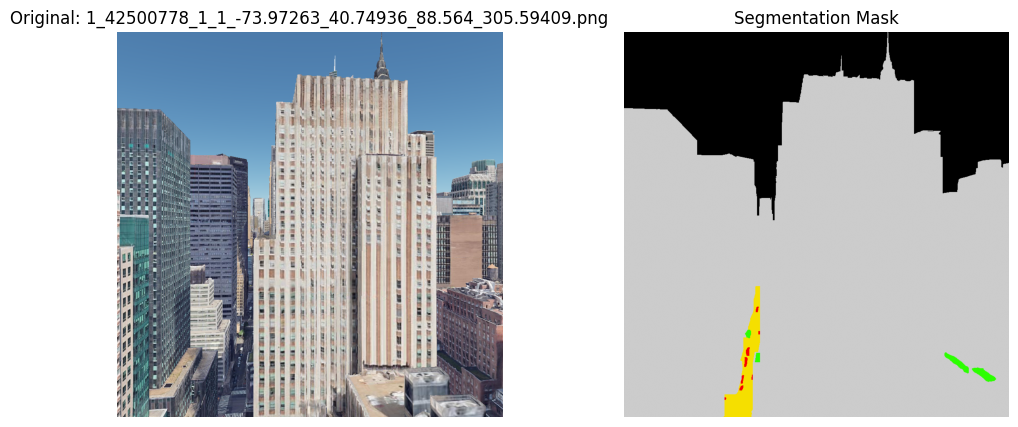

In [6]:
# Visualize the first sample from the NY training set
print("Visualizing NY sample...")
visualize_cimwv_sample(NY_DIR, ny_train, index=0)

# Data distribution

In [39]:
# using only hong kong because the other datasets are too small for evaluation
TEST_SPLIT_DIR = os.path.join(HK_DIR, "ImageSets", "CIM_WV_all")
TEST_TXT_PATH = os.path.join(TEST_SPLIT_DIR, "test.txt")
MASK_DIR = os.path.join(HK_DIR, "LabelledImages")

# --- 1. Define Class Mapping (PLACEHOLDER - Verify visually) ---
# The paper mentions: building, sky, vegetation, road, waterbody, vehicle, terrain
# You must check the unique IDs in the mask. Often 0 is background/unlabeled.


CIM_CLASS_MAPPING = {
    29:  "Sky",
    225: "Building",
    149: "Vegetation",
    170: "Road",
    58:  "Waterbody",
    197: "Vehicle",
    76:  "Terrain"
}

# --- 2. Load Test Filenames ---
with open(TEST_TXT_PATH, 'r') as f:
    test_filenames = [line.strip() for line in f.readlines() if line.strip()]

# Ensure extensions are handled
test_filenames = [f if f.endswith(('.jpg', '.png')) else f + ".jpg" for f in test_filenames]

print(f"Total HK Test images to evaluate: {len(test_filenames)}")

Total HK Test images to evaluate: 300


In [40]:
# --- 3. Calculate Distribution ---
def calculate_cimwv_distribution(filenames, sample_size=50):
    all_pixel_counts = {}
    image_counts = {}
    
    # Sample a subset for speed (or use all 300 if it's fast enough)
    sampled_filenames = filenames[:sample_size] 
    
    for fname in sampled_filenames:
        mask_fname = os.path.splitext(fname)[0] + ".png" # Usually masks are .png
        mask_path = os.path.join(MASK_DIR, mask_fname)
        
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue
            
        unique, counts = np.unique(mask, return_counts=True)
        for class_id, count in zip(unique, counts):
            if class_id not in all_pixel_counts:
                all_pixel_counts[class_id] = 0
                image_counts[class_id] = 0
            
            all_pixel_counts[class_id] += count
            image_counts[class_id] += 1 # Number of images containing this class
            
    df_dist = pd.DataFrame(list(all_pixel_counts.items()), columns=['Class_ID', 'Total_Pixels'])
    df_dist['Pixel_Percentage'] = (df_dist['Total_Pixels'] / df_dist['Total_Pixels'].sum()) * 100
    df_dist['Class_Name'] = df_dist['Class_ID'].map(CIM_CLASS_MAPPING).fillna("Unknown")
    
    df_dist['Image_Count'] = df_dist['Class_ID'].map(image_counts)
    df_dist['Image_Percentage'] = (df_dist['Image_Count'] / len(sampled_filenames)) * 100
    
    return df_dist.sort_values(by='Class_ID')

print("--- CIM-WV Class Distribution (Sampled HK Test Set) ---")
dist_df = calculate_cimwv_distribution(test_filenames, sample_size=50) # Use 50 for quick check
print(dist_df.to_string(index=False))

--- CIM-WV Class Distribution (Sampled HK Test Set) ---
 Class_ID  Total_Pixels  Pixel_Percentage Class_Name  Image_Count  Image_Percentage
       29       5016265         12.385840        Sky           44              88.0
       58        308386          0.761447  Waterbody            5              10.0
       76          4708          0.011625    Terrain           12              24.0
      149       1792710          4.426444 Vegetation           40              80.0
      170        900365          2.223123       Road           31              62.0
      197         44377          0.109573    Vehicle           12              24.0
      225      32433189         80.081948   Building           50             100.0


In [41]:
dist_df.shape

(7, 6)

From `Class_ID` we fund these IDs:

       29  
       58      
       76       
      149       
      170        
      197        
      225   

So let's look at them

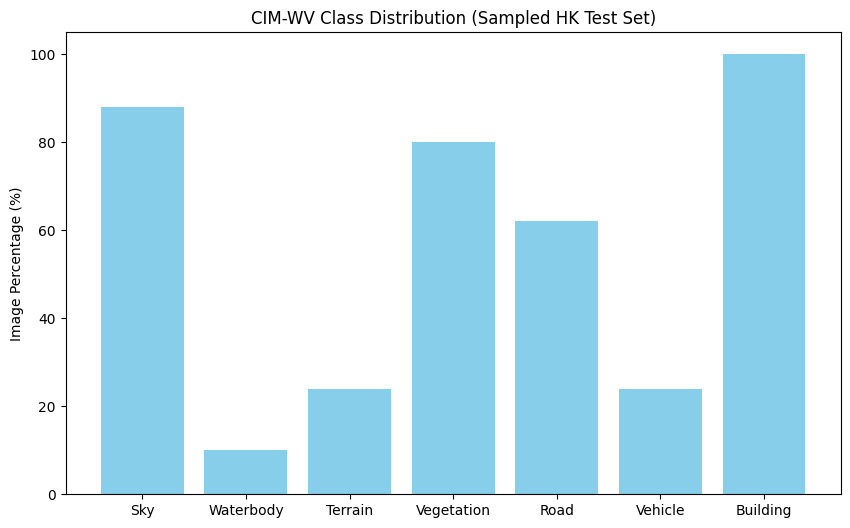

In [44]:
# plotting the distribution by Class_ID count
plt.figure(figsize=(10, 6))
plt.bar(dist_df['Class_Name'], dist_df['Image_Percentage'], color='skyblue')
plt.title("CIM-WV Class Distribution (Sampled HK Test Set)")
plt.ylabel("Image Percentage (%)")
plt.show()

Checking ID 29...


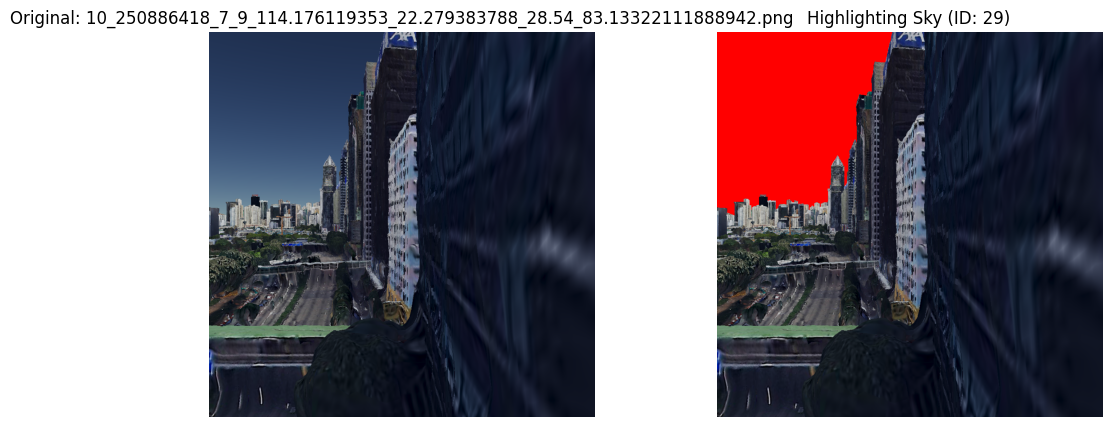

Checking ID 225...


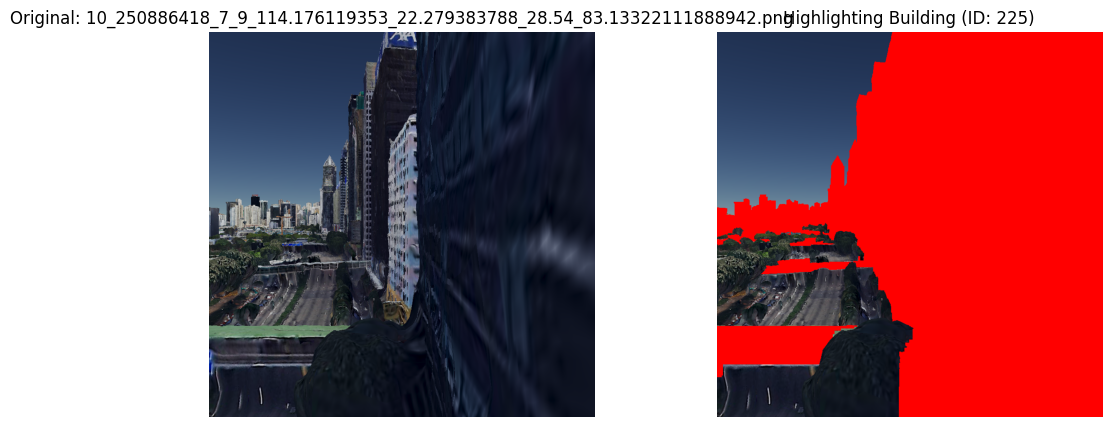

Checking ID 149...


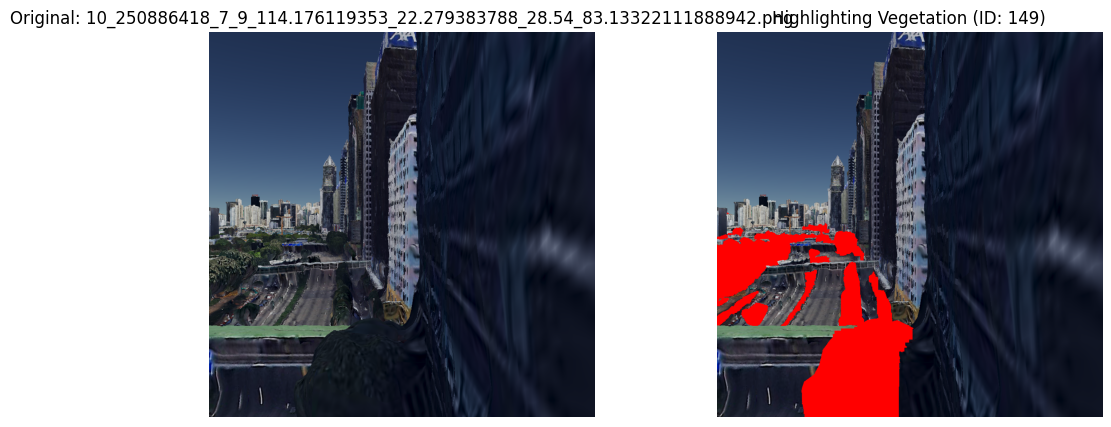

Checking ID 170...


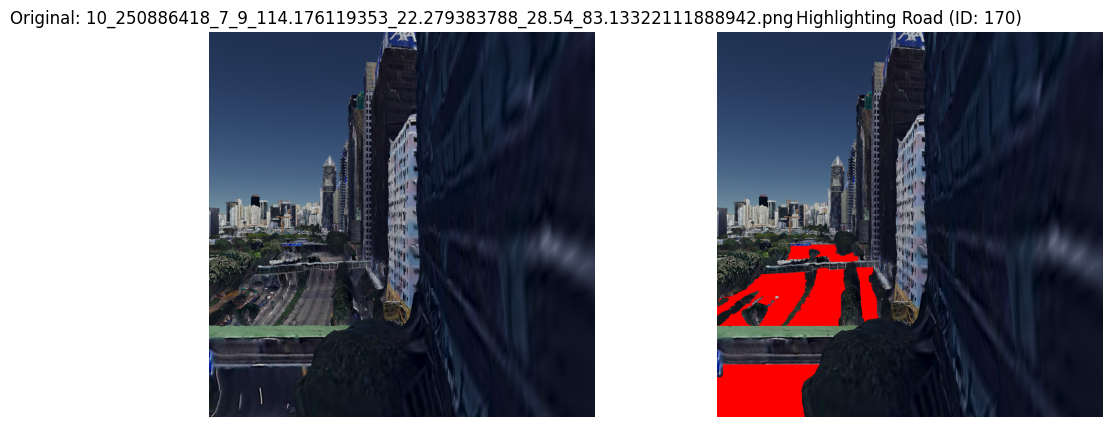

Checking ID 58...


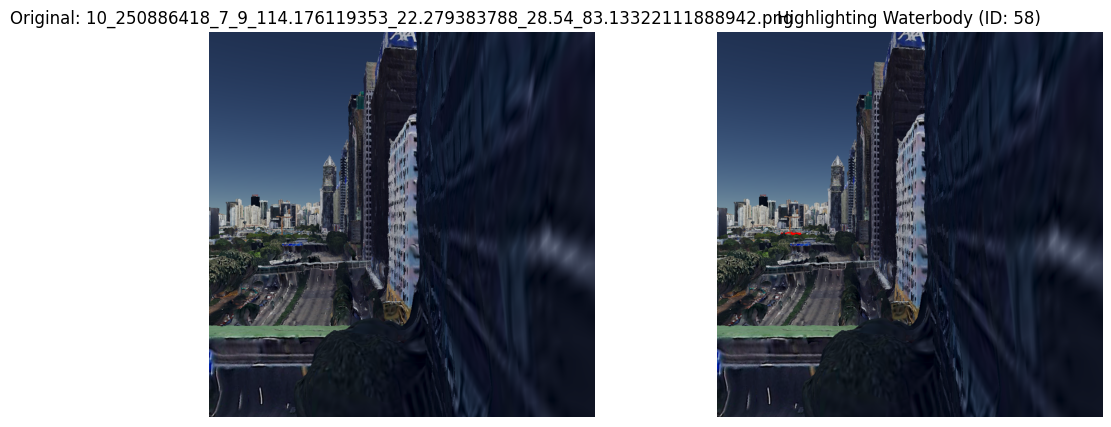

Checking ID 197...


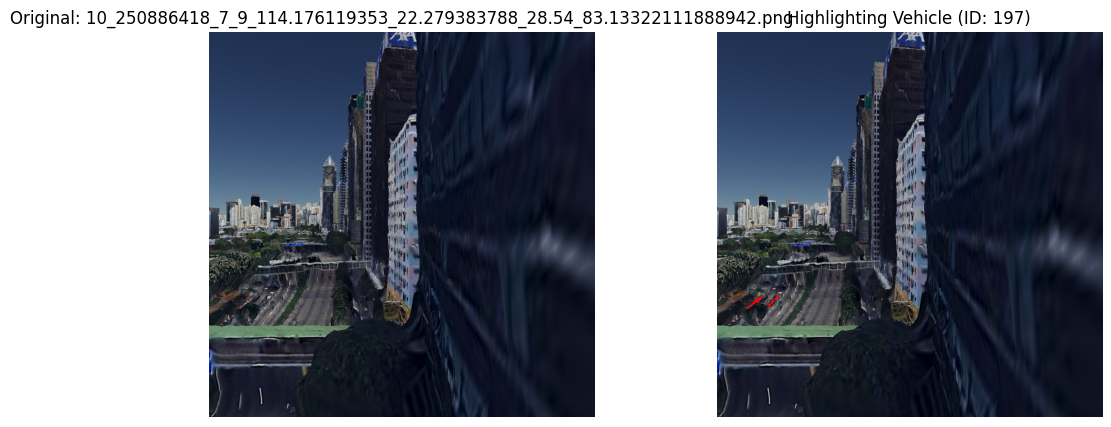

Checking ID 76...


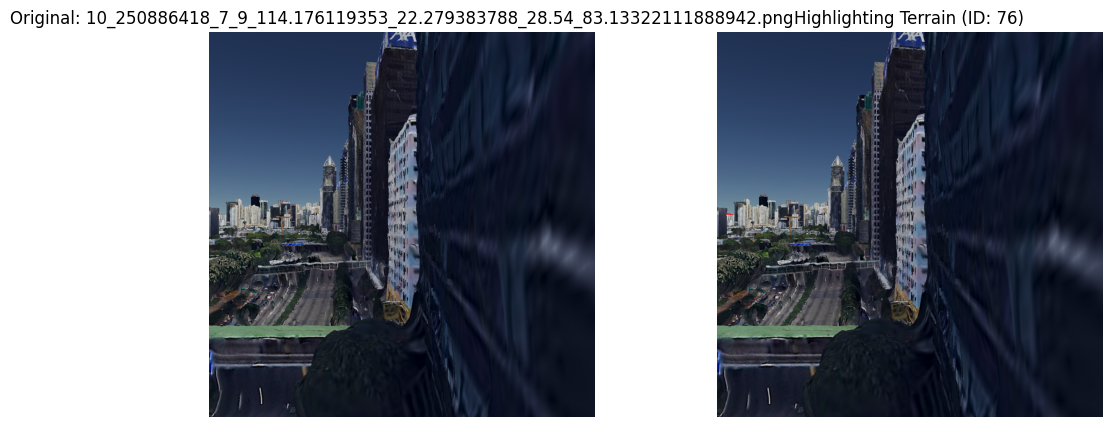

In [45]:
# mapping from visualized samples (reverse-engineered)
CIM_CLASS_MAPPING = {
    29: "Sky",
    225:  "Building",
    149: "Vegetation",
    170: "Road",
    58:  "Waterbody",
    197: "Vehicle",
    76:  "Terrain"
}

# --- 2. Visualize to Confirm ---
def visualize_cimwv_class(fname, target_class_id):
    mask_fname = os.path.splitext(fname)[0] + ".png"
    rgb_path = os.path.join(HK_DIR, "JPEGImages", fname)
    mask_path = os.path.join(HK_DIR, "LabelledImages", mask_fname)
    
    image = cv2.cvtColor(cv2.imread(rgb_path), cv2.COLOR_BGR2RGB)
    # Load the mask exactly as it is stored
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) 
    
    overlay = image.copy()
    overlay[mask == target_class_id] = [255, 0, 0] # Highlight target class in RED
    
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(f"Original: {fname}")
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title(f"Highlighting {CIM_CLASS_MAPPING.get(target_class_id, 'Unknown')} (ID: {target_class_id})")
    plt.axis('off')
    plt.show()

# Test it on the first test image
test_image = test_filenames[24]

print("Checking ID 29...")
visualize_cimwv_class(test_image, 29)  # Should highlight the buildings

print("Checking ID 225...")
visualize_cimwv_class(test_image, 225) # Should highlight the sky

print("Checking ID 149...")
visualize_cimwv_class(test_image, 149) # Should highlight vegetation

print("Checking ID 170...")
visualize_cimwv_class(test_image, 170) # Should highlight the road

print("Checking ID 58...")
visualize_cimwv_class(test_image, 58) # Should highlight the waterbody

print("Checking ID 197...")
visualize_cimwv_class(test_image, 197) # Should highlight vehicles

print("Checking ID 76...")
visualize_cimwv_class(test_image, 76) # Should highlight terrain


        225 is sky
        29 is building
        149 is vegetation
        170 is road
        58 is waterbody
        197 is vehicle
        76 is terrain